# 15. Reject option for the stage-2 race classifier

Notebook 14 ended with a recommendation, which it called the most actionable result it had produced. Stage 2 names 11 of 11 races correctly, but shown a cage failure, a compound failure or a combined inner+outer failure it calls every one of them outer race, at 0.81–0.96 confidence against 0.91 when it is right. The proposed fix was a reject option: keep the two-class model, but require positive evidence for the class it names, so that the answer can be "outer race, inner race, or I don't recognise this". Notebook 14 judged that achievable with the data already in hand, and recorded it as option 2 against the alternative of adding cage and compound as trained classes.

This notebook tests it. The reject option does not work: not with any of the rules notebook 14 named, not with more features, and not when the out-of-scope labels are handed to a model directly. The cause is not a modelling shortfall. The four out-of-scope units are not out of distribution. Two of them raise BPFO, one raises nothing at all and so sits in the middle of the training data, and the fourth is distinctive only in the quiet direction. The cage frequency that should have named both cage failures is flat on both.

The protocol is notebook 14's throughout, unchanged so the comparison holds: stage-1 alarms from RMS + kurtosis against each unit's own first twenty healthy minutes, stage-2 features as the change in envelope order bands from that same baseline, leave-one-bearing-out over the eleven race-labelled units. We added four ways of asking "is this one of mine?": the two notebook 14 named (a distance-to-training-distribution test and a one-class model per race), the model confidence it had already found wanting, and a nearest-neighbour distance. We then put the question to Paderborn, where KA22 has been a known out-of-scope case since notebook 06.

In [1]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.covariance import LedoitWolf
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve

OUT = pathlib.Path("../data/processed")
ds = pd.read_csv(OUT / "xjtu_envelope_features.csv")     # built by notebook 13

FAULT = {"Bearing1_1": "OR", "Bearing1_2": "OR", "Bearing1_3": "OR",
         "Bearing1_4": "cage", "Bearing1_5": "IR+OR", "Bearing2_1": "IR",
         "Bearing2_2": "OR", "Bearing2_3": "cage", "Bearing2_4": "OR",
         "Bearing2_5": "OR", "Bearing3_1": "OR", "Bearing3_2": "compound",
         "Bearing3_3": "IR", "Bearing3_4": "IR", "Bearing3_5": "OR"}
BEAR = sorted(ds["Bearing"].unique())
RACE = [b for b in BEAR if FAULT[b] in ("OR", "IR")]     # the two classes stage 2 has
OTHER = [b for b in BEAR if b not in RACE]               # the four it has no name for
G = {b: ds[ds["Bearing"] == b].sort_values("Snapshot").reset_index(drop=True) for b in BEAR}
N = {b: len(G[b]) for b in BEAR}

ENV = ["H_BPFO", "H_BPFI", "H_FR", "H_BPFO_h2", "H_BPFI_h2", "H_BSF", "H_FTF",
       "H_BPFI_sb1", "H_BPFO_sb1"]
DETECT = ["H_RMS", "H_Kurt"]
K, W = 20, 10
RF = dict(n_estimators=300, random_state=0, n_jobs=-1)
CAP = 80                                                 # snapshots per unit when pooling


class Exceedance:
    """Robust per-feature z over the unit's own healthy baseline (notebook 07)."""

    def fit(self, A):
        self.med = np.median(A, axis=0)
        self.mad = np.maximum(1.4826 * np.median(np.abs(A - self.med), axis=0), 0.1)
        return self

    def score(self, A):
        return ((A - self.med) / self.mad).max(axis=1)


def sustained(flags, offset):
    c = np.convolve(flags.astype(float), np.ones(W) / W, mode="valid")
    hit = np.flatnonzero(c >= 0.5)
    return None if hit.size == 0 else int(hit[0]) + offset


ALARM = {}
for b in BEAR:
    A = G[b][DETECT].to_numpy()
    m = Exceedance().fit(A[:K])
    ALARM[b] = sustained(m.score(A)[K:] > np.quantile(m.score(A[:K]), 0.99), K)

RAW = {b: G[b][ENV].to_numpy() for b in BEAR}
DELTA = {b: RAW[b] - np.median(RAW[b][:K], axis=0) for b in BEAR}
POST = {b: DELTA[b][ALARM[b]:] for b in BEAR}             # notebook 14's stage-2 input

RULES = ["model confidence", "Mahalanobis to class centre",
         "10-nearest-neighbour distance", "one-class forest"]


def fit_rules(X, y):
    """Notebook 14's two-class model, plus four ways of asking 'is this one of mine?'.
    Every scorer returns HIGH = less like the training classes."""
    clf = RandomForestClassifier(**RF).fit(X, y)
    sc = StandardScaler().fit(X)
    Z = sc.transform(X)
    cls = sorted(np.unique(y))
    ctr = {c: (Z[y == c].mean(axis=0),
               np.linalg.pinv(LedoitWolf().fit(Z[y == c]).covariance_)) for c in cls}
    nn = {c: NearestNeighbors(n_neighbors=10).fit(Z[y == c]) for c in cls}
    oc = {c: IsolationForest(n_estimators=200, random_state=0).fit(Z[y == c]) for c in cls}

    def score(A):
        Za = sc.transform(A)
        s = {"model confidence": 1 - clf.predict_proba(A).max(axis=1)}
        s["Mahalanobis to class centre"] = np.column_stack(
            [np.sqrt(np.einsum("ij,jk,ik->i", Za - ctr[c][0], ctr[c][1], Za - ctr[c][0]))
             for c in cls]).min(axis=1)
        s["10-nearest-neighbour distance"] = np.column_stack(
            [nn[c].kneighbors(Za)[0].mean(axis=1) for c in cls]).min(axis=1)
        s["one-class forest"] = np.column_stack(
            [-oc[c].decision_function(Za) for c in cls]).min(axis=1)
        return clf.predict(A), s

    return score


def cap(a, n=CAP):
    """Even-spaced thinning, so a 2538-minute unit does not outvote a 42-minute one."""
    return a if len(a) <= n else a[np.linspace(0, len(a) - 1, n).astype(int)]


C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
FCOLOR = {"OR": C_BLUE, "IR": C_ORANGE, "cage": "#7a9e3f",
          "IR+OR": "#8f6bb5", "compound": MUTED}
RCOLOR = dict(zip(RULES, [INK2, C_BLUE, C_ORANGE, "#7a9e3f"]))

print(f"{len(RACE)} race units in scope, {len(OTHER)} out of scope: "
      + ', '.join(b.replace('Bearing', '') + ' (' + FAULT[b] + ')' for b in OTHER))
print(f"post-alarm snapshots: {sum(len(POST[b]) for b in RACE)} in scope, "
      f"{sum(len(POST[b]) for b in OTHER)} out of scope")

11 race units in scope, 4 out of scope: 1_4 (cage), 1_5 (IR+OR), 2_3 (cage), 3_2 (compound)
post-alarm snapshots: 1131 in scope, 1356 out of scope


## Four scores for rejecting a snapshot

A reject option needs a score that is high when a snapshot is unlike everything the model was trained on, and a threshold on it. We tested four scores. All are fitted on the same training set as the classifier, and all are oriented so that a high value means less like the training classes.

- Model confidence: one minus the winning class probability. Notebook 14 showed this carries no unit-level signal. It is included as the baseline any real rule has to beat.
- Mahalanobis to class centre: distance to the nearer of the two class means under a Ledoit–Wolf covariance. This is the plain reading of notebook 14's "distance-to-training-distribution test".
- 10-nearest-neighbour distance: mean distance to the ten closest training snapshots of the nearer class. It does not assume the class is one ellipsoid.
- One-class forest: an isolation forest fitted per race, which is notebook 14's "one-class model per race", scored as the more inlying of the two.

In-scope and out-of-scope snapshots must be scored by models that have not seen them. Every fold trains on ten race units. The eleventh is scored by a model that never saw it, and that is the in-scope population: the snapshots a deployed rule must keep. The four out-of-scope units are scored by all eleven fold models and averaged, so in-scope and out-of-scope scores come from models of the same kind trained on the same amount of data. Nothing is fitted on a cage, compound or combined unit.

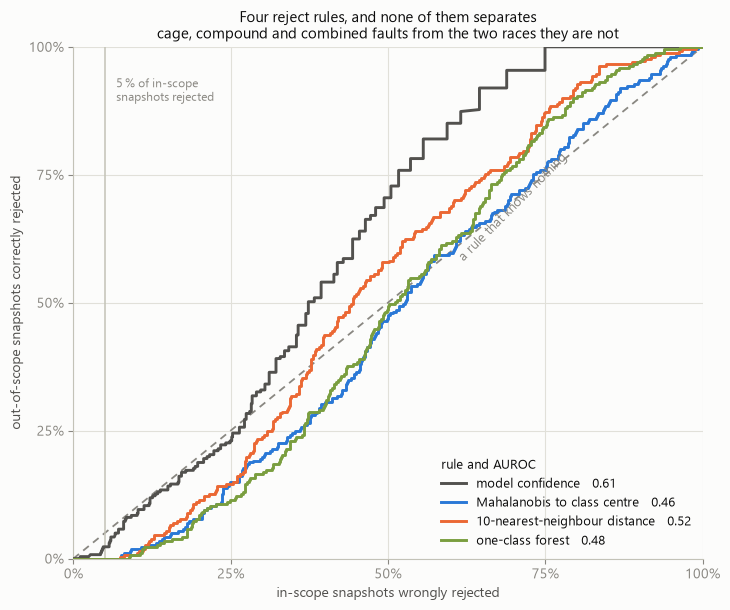

stage 2 unchanged from notebook 14: 94.1% of snapshots, 11/11 bearings


,auroc,rejected_at_95
rule,,
model confidence,0.613,2.3%
Mahalanobis to class centre,0.463,0.0%
10-nearest-neighbour distance,0.523,0.0%
one-class forest,0.480,0.0%


In [2]:
# leave-one-bearing-out: the held-out unit is scored by a model that never saw it,
# and so are the four out-of-scope units, by every one of the eleven fold models.
IN = {}
OOS_S = {b: {r: [] for r in RULES} for b in OTHER}
OOS_P = {b: [] for b in OTHER}
for held in RACE:
    tr = [o for o in RACE if o != held]
    score = fit_rules(np.vstack([POST[o] for o in tr]),
                      np.concatenate([[FAULT[o]] * len(POST[o]) for o in tr]))
    pred, s = score(POST[held])
    IN[held] = dict(pred=pred, **s)
    for b in OTHER:
        p2, s2 = score(POST[b])
        OOS_P[b].append(p2)
        for r in RULES:
            OOS_S[b][r].append(s2[r])
OOS = {b: {r: np.mean(OOS_S[b][r], axis=0) for r in RULES} for b in OTHER}
for b in OTHER:
    OOS[b]["pred"] = pd.DataFrame(OOS_P[b]).mode(axis=0).iloc[0].to_numpy()

fig, ax = plt.subplots(figsize=(7.4, 6.2))
rows = []
for r in RULES:
    i = np.concatenate([cap(IN[b][r]) for b in RACE])
    o = np.concatenate([cap(OOS[b][r]) for b in OTHER])
    truth = np.r_[np.zeros(len(i)), np.ones(len(o))]
    fpr, tpr, _ = roc_curve(truth, np.r_[i, o])
    auc = roc_auc_score(truth, np.r_[i, o])
    ax.plot(fpr, tpr, color=RCOLOR[r], lw=2.1, zorder=3, label=f"{r}   {auc:.2f}")
    rows.append(dict(rule=r, auroc=auc,
                     rejected_at_95=(o > np.quantile(i, 0.95)).mean()))
ax.plot([0, 1], [0, 1], color=MUTED, lw=1.3, ls=(0, (4, 3)), zorder=2)
ax.text(0.62, 0.58, "a rule that knows nothing", color=MUTED, fontsize=9,
        rotation=45, rotation_mode="anchor")
ax.axvline(0.05, color=BASE, lw=1.1, zorder=2)
ax.text(0.068, 0.94, "5 % of in-scope\nsnapshots rejected", color=MUTED, fontsize=8.5,
        va="top")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("in-scope snapshots wrongly rejected")
ax.set_ylabel("out-of-scope snapshots correctly rejected")
ax.legend(fontsize=9, loc="lower right", title="rule and AUROC",
          title_fontsize=9, alignment="left")
ax.set_title("Four reject rules, and none of them separates\n"
             "cage, compound and combined faults from the two races they are not",
             fontsize=11)
plt.tight_layout()
plt.show()

snap = np.mean([(IN[b]["pred"] == FAULT[b]).mean() for b in RACE])
vote = sum(pd.Series(IN[b]["pred"]).mode()[0] == FAULT[b] for b in RACE)
print(f"stage 2 unchanged from notebook 14: {snap:.1%} of snapshots, {vote}/{len(RACE)} bearings")
sep = pd.DataFrame(rows).set_index("rule")
sep.style.format({"auroc": "{:.3f}", "rejected_at_95": "{:.1%}"})

All four rules sit on the diagonal, and three of them sit below it. Model confidence reaches 0.613 AUROC, the 10-nearest-neighbour distance 0.523, the one-class forest 0.480 and the Mahalanobis distance 0.463. The last is worse than guessing: cage, compound and combined snapshots are on average closer to a race class centre than race snapshots are.

At the operating point a deployment would choose (reject 5 % of in-scope snapshots, the most any monitoring system would tolerate), confidence rejects 2.3 % of out-of-scope snapshots and the other three rules reject none at all. Stage 2 itself is unchanged at 94.1 % and 11 of 11, so the reject option does not trade accuracy for caution. There is nothing to trade: the rules cannot find the four units at any threshold.

This refutes notebook 14's option 2 as stated. One objection remains: nine envelope order bands from one accelerometer may be too thin a space to measure novelty in.

## Adding features

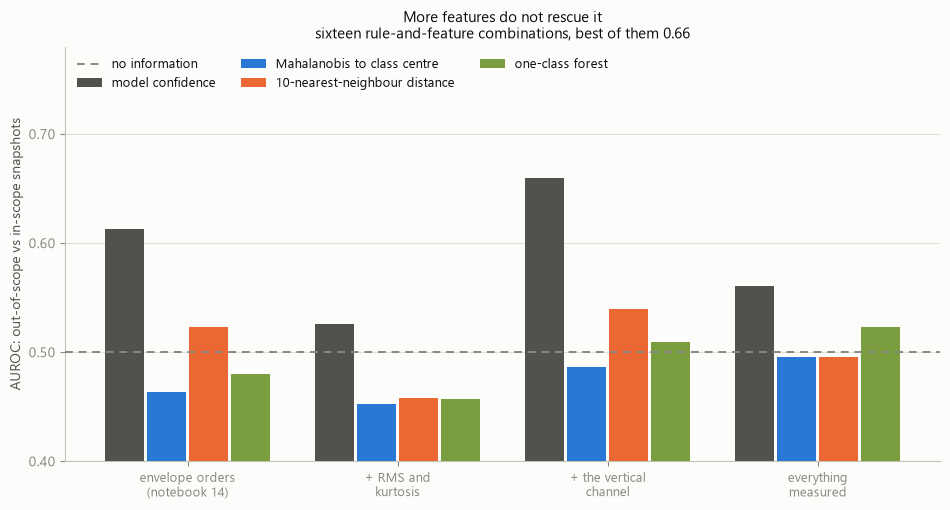

best combination: ('+ the vertical channel', 'model confidence') at 0.660


,model confidence,Mahalanobis to class centre,10-nearest-neighbour distance,one-class forest
envelope orders (notebook 14),0.613,0.463,0.523,0.480
+ RMS and kurtosis,0.526,0.453,0.458,0.457
+ the vertical channel,0.660,0.487,0.539,0.509
everything measured,0.561,0.495,0.496,0.523


In [3]:
V = [c.replace("H_", "V_") for c in ENV]
SETS = {"envelope orders\n(notebook 14)": ENV,
        "+ RMS and\nkurtosis": ENV + DETECT,
        "+ the vertical\nchannel": ENV + V,
        "everything\nmeasured": ENV + V + DETECT + ["V_RMS", "V_Kurt"]}


def post_for(feats):
    out = {}
    for b in BEAR:
        A = G[b][feats].to_numpy()
        out[b] = (A - np.median(A[:K], axis=0))[ALARM[b]:]
    return out


sweep = {}
for name, feats in SETS.items():
    P = post_for(feats)
    ins = {r: [] for r in RULES}
    oos = {r: {b: [] for b in OTHER} for r in RULES}
    for held in RACE:
        tr = [o for o in RACE if o != held]
        score = fit_rules(np.vstack([P[o] for o in tr]),
                          np.concatenate([[FAULT[o]] * len(P[o]) for o in tr]))
        _, s = score(P[held])
        for r in RULES:
            ins[r].append(cap(s[r]))
        for b in OTHER:
            _, s2 = score(P[b])
            for r in RULES:
                oos[r][b].append(s2[r])
    for r in RULES:
        i = np.concatenate(ins[r])
        o = np.concatenate([cap(np.mean(oos[r][b], axis=0)) for b in OTHER])
        sweep[(name, r)] = roc_auc_score(
            np.r_[np.zeros(len(i)), np.ones(len(o))], np.r_[i, o])

fig, ax = plt.subplots(figsize=(9.6, 5.2))
x = np.arange(len(SETS))
for j, r in enumerate(RULES):
    ax.bar(x + (j - 1.5) * 0.2, [sweep[(n, r)] for n in SETS], width=0.185,
           color=RCOLOR[r], zorder=3, label=r)
ax.axhline(0.5, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=4, label="no information")
ax.set_xticks(x, list(SETS), fontsize=9)
ax.set_ylim(0.4, 0.78)
ax.set_yticks([.4, .5, .6, .7], ["0.40", "0.50", "0.60", "0.70"])
ax.set_ylabel("AUROC: out-of-scope vs in-scope snapshots")
ax.grid(axis="x", visible=False)
ax.legend(fontsize=9, loc="upper left", ncol=3)
ax.set_title("More features do not rescue it\n"
             "sixteen rule-and-feature combinations, best of them 0.66", fontsize=11)
plt.tight_layout()
plt.show()

tbl = pd.DataFrame({r: {n.replace(chr(10), " "): sweep[(n, r)] for n in SETS}
                    for r in RULES})
print(f"best combination: {tbl.stack().idxmax()} at {tbl.stack().max():.3f}")
tbl.style.format("{:.3f}")

More features do not help. Sixteen rule-and-feature combinations span 0.453 to 0.660, and the best of them, confidence with the vertical accelerometer added, is still far short of anything usable. Adding RMS and kurtosis makes every rule worse. That fits what these features are: the stage-1 channel, large and rising in every post-alarm snapshot regardless of fault type, so they swamp the geometry. Doubling the sensor count by adding the vertical channel moves the distance rules by 0.02–0.03.

The failure is therefore not a shortage of features. Something about these four units makes them un-novel, and the features are detailed enough to show what.

## Why there is nothing to reject

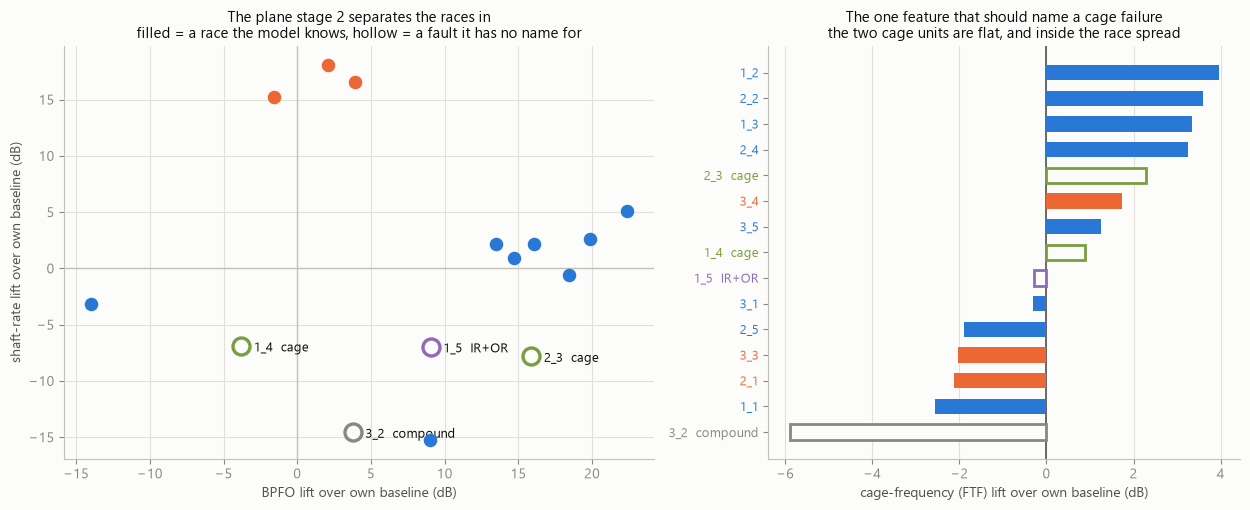

FTF lift, cage units: +0.9, +2.3 dB   | race units span -2.6 to +4.0 dB


,H_BPFO,H_BPFO_h2,H_FR,H_BPFI,H_FTF,H_BSF
truth,,,,,,
IR,+2.1,+0.2,+16.6,+5.1,-2.0,+5.6
IR+OR,+9.1,+14.8,-7.0,+1.6,-0.3,+0.8
OR,+15.4,+12.6,+1.6,-0.3,+2.2,+2.5
cage,+6.0,+7.2,-7.3,+0.5,+1.6,-0.2
compound,+3.8,+2.1,-14.6,+1.0,-5.9,-4.3


In [4]:
# the developed signature: median change from own baseline over the last fifth of life
DEV = {}
for b in BEAR:
    A = POST[b]
    DEV[b] = np.median(A[int(0.8 * len(A)):], axis=0)
dev = pd.DataFrame(DEV, index=ENV).T
dev.insert(0, "truth", [FAULT[b] for b in BEAR])

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.6, 5.2),
                               gridspec_kw=dict(width_ratios=[1.25, 1]))
for b in BEAR:
    inb = b in RACE
    axa.scatter(dev.loc[b, "H_BPFO"], dev.loc[b, "H_FR"], s=150 if not inb else 95,
                color=FCOLOR[FAULT[b]] if inb else SURFACE,
                edgecolors=FCOLOR[FAULT[b]], linewidths=0 if inb else 2.4, zorder=4)
    if not inb:
        axa.annotate(f'{b.replace("Bearing", "")}  {FAULT[b]}',
                     (dev.loc[b, "H_BPFO"], dev.loc[b, "H_FR"]),
                     textcoords="offset points", xytext=(9, -4), fontsize=9, color=INK)
axa.axhline(0, color=BASE, lw=1)
axa.axvline(0, color=BASE, lw=1)
axa.set_xlabel("BPFO lift over own baseline (dB)")
axa.set_ylabel("shaft-rate lift over own baseline (dB)")
axa.set_title("The plane stage 2 separates the races in\n"
              "filled = a race the model knows, hollow = a fault it has no name for",
              fontsize=10.5)

y = np.arange(len(BEAR))
order = sorted(BEAR, key=lambda b: dev.loc[b, "H_FTF"])
for i, b in enumerate(order):
    inb = b in RACE
    axb.barh(i, dev.loc[b, "H_FTF"], height=0.6, zorder=3,
             color=FCOLOR[FAULT[b]] if inb else SURFACE,
             edgecolor=FCOLOR[FAULT[b]], linewidth=0 if inb else 2.0)
axb.axvline(0, color=INK2, lw=1.2)
axb.set_yticks(y, [b.replace("Bearing", "") + ("  " + FAULT[b] if b in OTHER else "")
                   for b in order], fontsize=9)
for i, b in enumerate(order):
    axb.get_yticklabels()[i].set_color(FCOLOR[FAULT[b]])
axb.set_xlabel("cage-frequency (FTF) lift over own baseline (dB)")
axb.grid(axis="y", visible=False)
axb.set_title("The one feature that should name a cage failure\n"
              "the two cage units are flat, and inside the race spread", fontsize=10.5)
plt.tight_layout()
plt.show()

cageftf = dev.loc[[b for b in BEAR if FAULT[b] == "cage"], "H_FTF"]
raceftf = dev.loc[RACE, "H_FTF"]
print(f"FTF lift, cage units: {', '.join(f'{v:+.1f}' for v in cageftf)} dB   "
      f"| race units span {raceftf.min():+.1f} to {raceftf.max():+.1f} dB")
dev.groupby("truth")[["H_BPFO", "H_BPFO_h2", "H_FR", "H_BPFI", "H_FTF", "H_BSF"]] \
   .median().style.format("{:+.1f}")

The four units are not out of distribution, and each is inside for a different reason. The group medians are +15.4 dB BPFO for outer race and +16.6 dB shaft rate for inner race. Against them:

- Bearing2_3 (cage) raises BPFO by +15.9 dB and its second harmonic by +15.9 dB. On the two features that define the outer-race class it cannot be told apart from an outer-race unit. In this feature space it is an outer-race signature, so calling it "outer race" is not a distribution failure.
- Bearing1_5 (inner + outer) raises BPFO +9.1 dB and 2 × BPFO +14.8 dB. The model is arguably not wrong here, since the unit has an outer-race fault. The answer is incomplete but not false, and no novelty score should be expected to flag a fault that contains a trained class.
- Bearing1_4 (cage) raises nothing: BPFO −3.8 dB, every band within a few dB of its own baseline. A snapshot near the origin is in the middle of the training data. A distance score cannot tell an invisible fault from a typical snapshot.
- Bearing3_2 (compound) is the only one with a distinctive signature at all: shaft rate −14.6 dB and FTF −5.9 dB, the lowest of all fifteen. It is distinctive in the quiet direction, which no rule trained on what damage looks like is tuned to notice.

The cage frequency does not name a cage failure. FTF lift for the two cage units is +0.9 and +2.3 dB, inside the −2.6 to +4.0 dB spread of the eleven race units. The one feature in this set whose physics is specific to the cage is flat on both units that failed by cage. This is the same structure notebook 06 found in KA15 and notebook 12 confirmed: a fault whose characteristic frequency carries no energy cannot be reached by any method built on that frequency. A reject option built on that frequency is another such method.

## Giving the model the out-of-scope labels

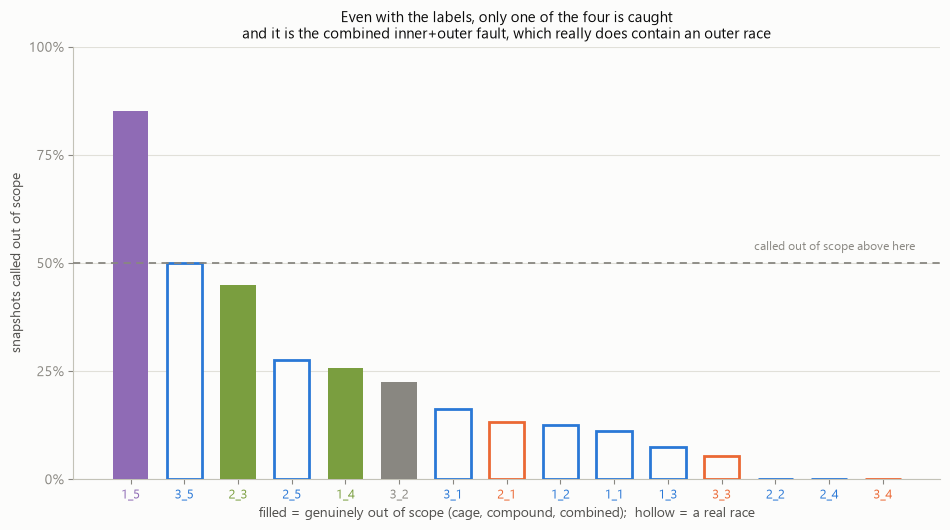

supervised in/out discriminator: 1/4 out-of-scope units caught, 11/11 race units kept, 12/15 units right
a model that always answers 'in scope' scores 11/15 and catches 0/4


,truth,scope,out,call
Bearing,,,,
Bearing1_4,cage,out of scope,26%,in scope
Bearing1_5,IR+OR,out of scope,85%,out of scope
Bearing2_3,cage,out of scope,45%,in scope
Bearing3_2,compound,out of scope,22%,in scope
Bearing1_1,OR,in scope,11%,in scope
Bearing1_2,OR,in scope,12%,in scope
Bearing1_3,OR,in scope,8%,in scope
Bearing2_1,IR,in scope,13%,in scope
Bearing2_2,OR,in scope,0%,in scope


In [5]:
# The unsupervised rules never see the out-of-scope labels. Give a model those labels,
# and ask the easier question directly: in scope, or not?
PC = {b: cap(POST[b]) for b in BEAR}
SCOPE = {b: ("in scope" if b in RACE else "out of scope") for b in BEAR}

rows = []
for held in BEAR:
    tr = [o for o in BEAR if o != held]
    m = RandomForestClassifier(**RF, class_weight="balanced").fit(
        np.vstack([PC[o] for o in tr]),
        np.concatenate([[SCOPE[o]] * len(PC[o]) for o in tr]))
    p = m.predict(PC[held])
    rows.append(dict(Bearing=held, truth=FAULT[held], scope=SCOPE[held],
                     out=(p == "out of scope").mean()))
sup = pd.DataFrame(rows).set_index("Bearing")
sup["call"] = np.where(sup["out"] > 0.5, "out of scope", "in scope")
sup["ok"] = sup["call"] == sup["scope"]

fig, ax = plt.subplots(figsize=(9.6, 5.4))
order = sorted(BEAR, key=lambda b: -sup.loc[b, "out"])
x = np.arange(len(order))
ax.bar(x, [sup.loc[b, "out"] for b in order], width=0.66, zorder=3,
       color=[FCOLOR[FAULT[b]] if b in OTHER else SURFACE for b in order],
       edgecolor=[FCOLOR[FAULT[b]] for b in order],
       linewidth=[0 if b in OTHER else 2.0 for b in order])
ax.axhline(0.5, color=MUTED, lw=1.3, ls=(0, (4, 3)), zorder=4)
ax.text(len(order) - 0.4, 0.53, "called out of scope above here", fontsize=8.5,
        color=MUTED, ha="right")
ax.set_xticks(x, [b.replace("Bearing", "") for b in order], fontsize=9.5)
for i, b in enumerate(order):
    ax.get_xticklabels()[i].set_color(FCOLOR[FAULT[b]])
ax.set_ylim(0, 1.0)
ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_ylabel("snapshots called out of scope")
ax.set_xlabel("filled = genuinely out of scope (cage, compound, combined);  "
              "hollow = a real race")
ax.grid(axis="x", visible=False)
ax.set_title("Even with the labels, only one of the four is caught\n"
             "and it is the combined inner+outer fault, which really does contain an outer race",
             fontsize=11)
plt.tight_layout()
plt.show()

caught = int(sup.loc[OTHER, "ok"].sum())
kept = int(sup.loc[RACE, "ok"].sum())
print(f"supervised in/out discriminator: {caught}/{len(OTHER)} out-of-scope units caught, "
      f"{kept}/{len(RACE)} race units kept, {int(sup['ok'].sum())}/{len(BEAR)} units right")
print(f"a model that always answers 'in scope' scores {len(RACE)}/{len(BEAR)} "
      f"and catches 0/{len(OTHER)}")
sup.loc[OTHER + RACE, ["truth", "scope", "out", "call"]].style.format({"out": "{:.0%}"})

This is the generous version of the question. A reject option never sees an out-of-scope fault. A supervised in-scope-versus-out-of-scope classifier does, and leave-one-unit-out over all fifteen shows whether the information is present at all, independent of whether an unsupervised rule could find it.

With the labels, one of the four is caught. Bearing1_5 is called out of scope on 85 % of its snapshots. It is the combined inner+outer fault, the one case where "out of scope" is the least defensible answer, since an outer-race call is half right. The two cage units and the compound unit are called in scope (26 %, 45 % and 23 % of snapshots flagged, all below the line), and Bearing3_5, an outer-race unit, sits exactly at 50 %.

The classifier scores 12 of 15 units, against 11 of 15 for a model that always answers "in scope" and catches nothing. The margin is one unit, and it comes from Bearing1_5, where rejection is the least defensible answer. The out-of-scope information is hard for an unsupervised rule to find, and even with the labels, four units and the answer key it is barely there.

This closes notebook 14's scope question in both directions. Adding cage and compound as trained classes needs data the project does not have. A reject option needs a signal these features do not carry. Neither option is available, and what stage 2 can deliver remains "outer race or inner race, assuming it is one of the two".

## Using the same score to flag wrong calls

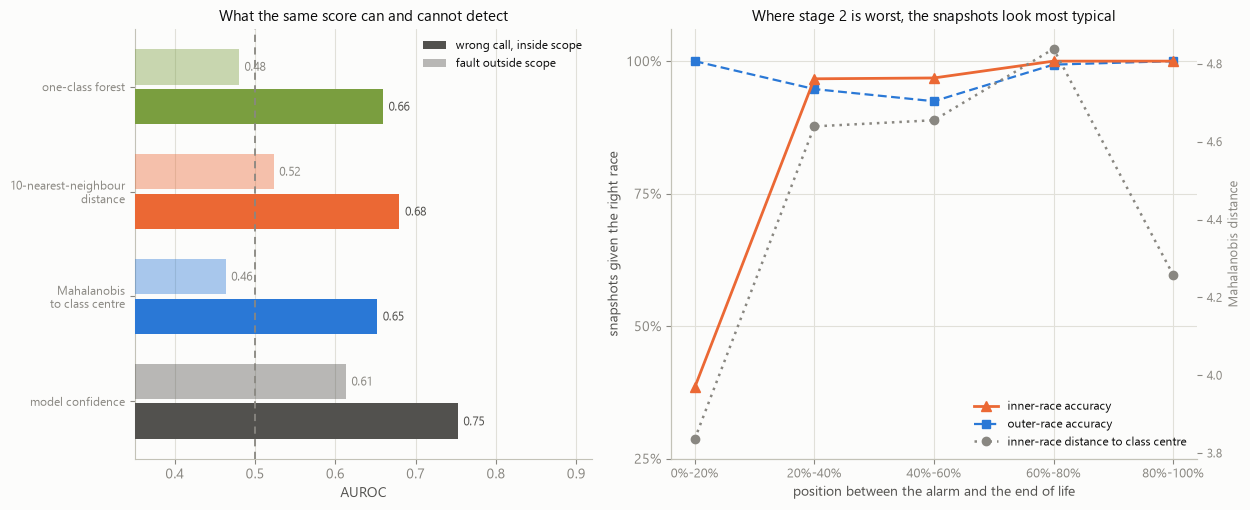

first fifth after the alarm: inner-race accuracy 38.4%, distance to class centre 3.84 - the lowest of the five bins (rest 4.26-4.84)
telling a wrong call from a right one: model confidence 0.752 AUROC, against 0.613 for out-of-scope


In [6]:
# Two different questions, same scores: "is this outside my classes?" (previous figures)
# and "am I about to get this wrong inside them?"
BINS = [(0.0, 0.2), (0.2, 0.4), (0.4, 0.6), (0.6, 0.8), (0.8, 1.0)]
LAB = [f"{a:.0%}-{b:.0%}" for a, b in BINS]
acc = {k: {"OR": [], "IR": []} for k in LAB}
nov = {r: {k: {"OR": [], "IR": []} for k in LAB} for r in RULES}
wrong, right = {r: [] for r in RULES}, {r: [] for r in RULES}

for held in RACE:
    ok = IN[held]["pred"] == FAULT[held]
    frac = np.linspace(0, 1, len(ok), endpoint=False)
    for (a, b_), k in zip(BINS, LAB):
        sel = (frac >= a) & (frac < b_)
        if sel.any():
            acc[k][FAULT[held]].append(ok[sel].mean())
            for r in RULES:
                nov[r][k][FAULT[held]].append(IN[held][r][sel].mean())
    for r in RULES:
        wrong[r].append(IN[held][r][~ok])
        right[r].append(IN[held][r][ok])

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.6, 5.2),
                               gridspec_kw=dict(width_ratios=[1, 1.15]))
within = {}
for r in RULES:
    w, g = np.concatenate(wrong[r]), np.concatenate(right[r])
    within[r] = roc_auc_score(np.r_[np.zeros(len(g)), np.ones(len(w))], np.r_[g, w])
y = np.arange(len(RULES))
axa.barh(y - 0.19, [within[r] for r in RULES], height=0.34, zorder=3,
         color=[RCOLOR[r] for r in RULES], label="wrong call, inside scope")
axa.barh(y + 0.19, [sep.loc[r, "auroc"] for r in RULES], height=0.34, zorder=3,
         color=[RCOLOR[r] for r in RULES], alpha=0.4,
         label="fault outside scope")
axa.axvline(0.5, color=MUTED, lw=1.3, ls=(0, (4, 3)), zorder=4)
for i, r in enumerate(RULES):
    axa.annotate(f"{within[r]:.2f}", (within[r], i - 0.19), xytext=(4, -3),
                 textcoords="offset points", fontsize=8.5, color=INK2)
    axa.annotate(f"{sep.loc[r, 'auroc']:.2f}", (sep.loc[r, "auroc"], i + 0.19),
                 xytext=(4, -3), textcoords="offset points", fontsize=8.5, color=MUTED)
axa.set_yticks(y, [r.replace(" to ", "\nto ").replace("-neighbour ", "-neighbour\n")
                   for r in RULES], fontsize=8.5)
axa.set_xlim(0.35, 0.92)
axa.grid(axis="y", visible=False)
axa.set_xlabel("AUROC")
axa.legend(fontsize=8.5, loc="upper right")
axa.set_title("What the same score can and cannot detect", fontsize=10.5)

xs = np.arange(len(LAB))
axb.plot(xs, [np.mean(acc[k]["IR"]) for k in LAB], color=C_ORANGE, lw=2.0,
         marker="^", ms=7, zorder=4, label="inner-race accuracy")
axb.plot(xs, [np.mean(acc[k]["OR"]) for k in LAB], color=C_BLUE, lw=1.6,
         marker="s", ms=6, ls=(0, (4, 2)), zorder=3, label="outer-race accuracy")
ax2 = axb.twinx()
mah = [np.mean(nov["Mahalanobis to class centre"][k]["IR"]) for k in LAB]
ax2.plot(xs, mah, color=MUTED, lw=1.8, marker="o", ms=6, ls=(0, (1, 2)), zorder=3,
         label="inner-race distance to class centre")
ax2.set_ylabel("Mahalanobis distance", color=MUTED, fontsize=9)
ax2.grid(visible=False)
ax2.tick_params(labelsize=8.5)
axb.set_xticks(xs, LAB, fontsize=9)
axb.set_ylim(0.25, 1.06)
axb.set_yticks([.25, .5, .75, 1.0], ["25%", "50%", "75%", "100%"])
axb.set_xlabel("position between the alarm and the end of life")
axb.set_ylabel("snapshots given the right race")
h1, l1 = axb.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
axb.legend(h1 + h2, l1 + l2, fontsize=8.5, loc="lower right")
axb.set_title("Where stage 2 is worst, the snapshots look most typical", fontsize=10.5)
plt.tight_layout()
plt.show()

print(f"first fifth after the alarm: inner-race accuracy {np.mean(acc[LAB[0]]['IR']):.1%}, "
      f"distance to class centre {mah[0]:.2f} - the lowest of the five bins "
      f"(rest {min(mah[1:]):.2f}-{max(mah[1:]):.2f})")
print(f"telling a wrong call from a right one: model confidence "
      f"{within['model confidence']:.3f} AUROC, against "
      f"{sep.loc['model confidence', 'auroc']:.3f} for out-of-scope")

Whether a snapshot is outside the model's classes and whether the model is about to be wrong inside them are different questions, and only the second has an answer here. Model confidence separates a wrong call from a right one at 0.752 AUROC, while separating out-of-scope from in-scope at 0.613. The distance rules also do better at separating wrong calls from right ones (0.652–0.680) than at separating out-of-scope from in-scope, but confidence is the best of them, and it is the one signal in this notebook that carries usable information.

The right-hand panel shows where the limit sits. Notebook 14's finding 6 was that inner-race attribution is 38.4 % correct in the first fifth after the alarm, which is below chance, and the wrong calls are labelled outer race. Distance to the class centre in that same bin is 3.84, the lowest of the five bins (the rest run 4.26–4.84). The snapshots stage 2 gets most wrong are the ones that look most typical of the training data. A freshly alarmed inner-race bearing has a small BPFO rise and no shaft-rate lift yet, which is a familiar early outer-race pattern. The confusion is between two known classes, not a novel fault, and a distance-based reject rule cannot reach it.

One result carries over to the explanation layer, in the narrower form the evidence supports. Stage 2 can flag "this call may be wrong" from confidence, at 0.75 AUROC. It cannot say "I don't recognise this". The first hedges a diagnosis within a known scope. The second is what a maintenance engineer needs when the fault is something the system has never been shown.

## Cross-rig check on Paderborn

Notebook 14 named the cross-rig check itself. KA22 is a real outer-race Paderborn bearing whose fault energy sits at order 5.5, not at BPFO. It is an off-frequency, non-tracking anomaly that notebooks 06 through 12 could sometimes detect but never attribute. It is the closest thing this project has to a labelled out-of-scope fault on a second rig. If a reject option flags it rather than guessing a race, that confirms the finding.

We tried two feature spaces, both at 400 N, where notebook 11's attribution was strongest: the fault-frequency features notebook 11 built, and a 40-band order profile that measures envelope energy everywhere between order 0.5 and 12, so that a line at 5.5 has somewhere to land. We then pointed the same machinery at a different reference population. The reference population is the variable that matters.

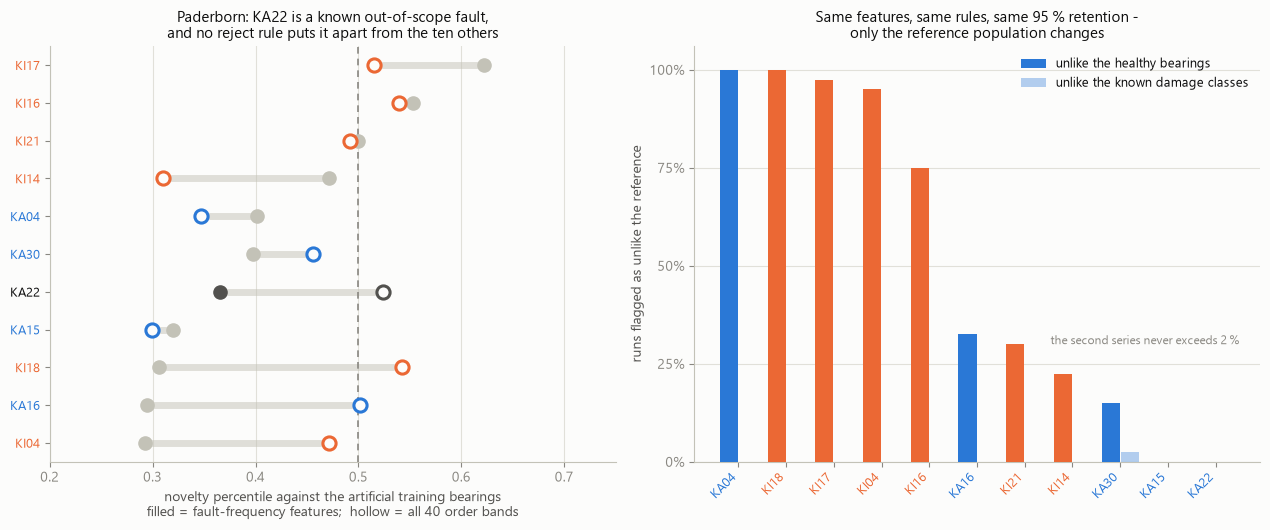

KA22 ranks 7 of 11 on fault-frequency features (37% against 42% for the rest), 3 of 11 on all 40 order bands (52% against 45%)
referenced to healthy: 5 of 11 bearings flagged on most runs, spread 0%-100%
referenced to known damage: 0 of 11, spread 0%-2%


In [7]:
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, hilbert, get_window

PU = pathlib.Path("../data/raw/paderborn")
LOAD = "N15_M07_F04"                                     # notebook 11's best attribution point
FS, N_KEEP, WIN = 64_000, 245_760, 65_536
N_SUB, HANN = N_KEEP // WIN, get_window("hann", WIN)
FREQ = np.fft.rfftfreq(WIN, 1 / FS)
FLOOR = (FREQ > 10) & (FREQ < 400)
SOS = butter(4, (1000, 20000), btype="bandpass", fs=FS, output="sos")
PU_BEARINGS = ([(f"K00{i}", "Healthy", "healthy") for i in range(1, 7)]
               + [(c, "OR", "artificial") for c in ("KA01", "KA03", "KA05", "KA07")]
               + [(c, "IR", "artificial") for c in ("KI01", "KI03", "KI05", "KI07")]
               + [(c, "OR", "real") for c in ("KA04", "KA15", "KA16", "KA22", "KA30")]
               + [(c, "IR", "real") for c in ("KI04", "KI14", "KI16", "KI17", "KI18", "KI21")])
PU_HEALTHY = [c for c, _, d in PU_BEARINGS if d == "healthy"]
PU_ART = [c for c, _, d in PU_BEARINGS if d == "artificial"]
PU_REAL = [c for c, _, d in PU_BEARINGS if d == "real"]
PU_LAB = {c: cls for c, cls, _ in PU_BEARINGS}
N_BAND, EDGES = 40, np.linspace(0.5, 12.0, 41)
BANDS = [f"B{i:02d}" for i in range(N_BAND)]


def build_bands(cond):
    """Envelope energy in 40 shaft-order bands - every order, not only BPFO and BPFI."""
    path = OUT / f"pu_{cond}_order_bands.csv"
    if path.exists():
        return pd.read_csv(path)
    rows = []
    for code, cls, dom in PU_BEARINGS:
        for run in range(1, 21):
            p = PU / code / f"{cond}_{code}_{run}.mat"
            ch = loadmat(p)[p.stem]["Y"][0, 0][0]
            c = {str(x["Name"][0]): x["Data"].squeeze() for x in ch}
            v = c["vibration_1"][:N_KEEP].astype(np.float64)
            fr = float(c["speed"].mean()) / 60
            e = np.abs(hilbert(sosfiltfilt(SOS, v)))
            w = (e - e.mean())[: N_SUB * WIN].reshape(N_SUB, WIN)
            spec = (np.abs(np.fft.rfft((w - w.mean(axis=1, keepdims=True)) * HANN,
                                       axis=1)) ** 2).mean(axis=0)
            fl, order = np.median(spec[FLOOR]), FREQ / fr
            r = {BANDS[i]: 10 * np.log10(
                spec[(order >= EDGES[i]) & (order < EDGES[i + 1])].max() / fl)
                for i in range(N_BAND)}
            r.update(Code=code, Condition=cls, Domain=dom, Run=run)
            rows.append(r)
    d = pd.DataFrame(rows)
    d.to_csv(path, index=False)
    return d


BND = build_bands(LOAD)
SB = pd.read_csv(OUT / f"pu_{LOAD}_sidebands.csv")
GEO = ["BPFO", "BPFI", "FR", "BPFI_sb1", "BPFO_sb1", "BPFI_sb2", "BPFI_h2_sb1"]


def pu_novelty(d, feats):
    """Train on the 8 artificial bearings; express each real run's novelty as a
    percentile of the held-out-artificial distribution."""
    tr = d[d["Domain"] == "artificial"]
    full = fit_rules(tr[feats].to_numpy(), tr["Condition"].to_numpy())
    calib = {r: [] for r in RULES}
    for held in PU_ART:
        t2 = tr[tr["Code"] != held]
        _, s = fit_rules(t2[feats].to_numpy(), t2["Condition"].to_numpy())(
            tr[tr["Code"] == held][feats].to_numpy())
        for r in RULES:
            calib[r].append(s[r])
    calib = {r: np.concatenate(calib[r]) for r in RULES}
    rows = []
    for b in PU_REAL:
        _, s = full(d[d["Code"] == b][feats].to_numpy())
        rows.append(dict(Code=b, truth=PU_LAB[b],
                         **{r: float(np.mean([(calib[r] < v).mean() for v in s[r]]))
                            for r in RULES}))
    return pd.DataFrame(rows).set_index("Code")[RULES].mean(axis=1)


geo = pu_novelty(SB, GEO)
bnd = pu_novelty(BND, BANDS)


def flagged(d, ref_codes):
    """How often is each real bearing unlike a chosen reference population?"""
    def fit(codes):
        X = d[d["Code"].isin(codes)][BANDS].to_numpy()
        sc = StandardScaler().fit(X)
        Z = sc.transform(X)
        mu, P = Z.mean(axis=0), np.linalg.pinv(LedoitWolf().fit(Z).covariance_)
        nn = NearestNeighbors(n_neighbors=10).fit(Z)

        def sc_fn(A):
            Za = sc.transform(A)
            return (np.sqrt(np.einsum("ij,jk,ik->i", Za - mu, P, Za - mu)),
                    nn.kneighbors(Za)[0].mean(axis=1))
        return sc_fn

    cm, ck = [], []
    for held in ref_codes:
        m, k = fit([c for c in ref_codes if c != held])(
            d[d["Code"] == held][BANDS].to_numpy())
        cm.append(m)
        ck.append(k)
    tm = np.quantile(np.concatenate(cm), 0.95)
    tk = np.quantile(np.concatenate(ck), 0.95)
    s = fit(ref_codes)
    out = {}
    for b in PU_REAL:
        m, k = s(d[d["Code"] == b][BANDS].to_numpy())
        out[b] = 0.5 * ((m > tm).mean() + (k > tk).mean())
    return pd.Series(out)


vs_healthy = flagged(BND, PU_HEALTHY)
vs_damage = flagged(BND, PU_ART)

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.4))
o1 = geo.sort_values(ascending=False).index
for i, b in enumerate(o1):
    hot = b == "KA22"
    axa.plot([geo[b], bnd[b]], [i, i], color=BASE, lw=5, alpha=0.5,
             solid_capstyle="round", zorder=2)
    axa.scatter([geo[b]], [i], s=90, color=INK2 if hot else BASE, zorder=4)
    axa.scatter([bnd[b]], [i], s=90, facecolors=SURFACE,
                edgecolors=INK2 if hot else FCOLOR[PU_LAB[b]], linewidths=2.2, zorder=4)
axa.set_yticks(range(len(o1)), list(o1), fontsize=9.5)
for i, b in enumerate(o1):
    axa.get_yticklabels()[i].set_color(INK if b == "KA22" else FCOLOR[PU_LAB[b]])
axa.invert_yaxis()
axa.axvline(0.5, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=3)
axa.set_xlim(0.2, 0.75)
axa.set_xlabel("novelty percentile against the artificial training bearings\n"
               "filled = fault-frequency features;  hollow = all 40 order bands")
axa.grid(axis="y", visible=False)
axa.set_title("Paderborn: KA22 is a known out-of-scope fault,\n"
              "and no reject rule puts it apart from the ten others", fontsize=10.5)

o2 = vs_healthy.sort_values(ascending=False).index
xs = np.arange(len(o2))
axb.bar(xs - 0.2, [vs_healthy[b] for b in o2], width=0.38, zorder=3,
        color=[FCOLOR[PU_LAB[b]] for b in o2], label="unlike the healthy bearings")
axb.bar(xs + 0.2, [vs_damage[b] for b in o2], width=0.38, zorder=3,
        color=[FCOLOR[PU_LAB[b]] for b in o2], alpha=0.35,
        label="unlike the known damage classes")
axb.set_xticks(xs, list(o2), fontsize=9, rotation=45, ha="right")
for i, b in enumerate(o2):
    axb.get_xticklabels()[i].set_color(FCOLOR[PU_LAB[b]])
axb.set_ylim(0, 1.06)
axb.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
axb.set_ylabel("runs flagged as unlike the reference")
axb.grid(axis="x", visible=False)
axb.legend(fontsize=9, loc="upper right")
axb.text(len(o2) - 0.5, 0.30, "the second series never exceeds 2 %", fontsize=8.5,
         color=MUTED, ha="right")
axb.set_title("Same features, same rules, same 95 % retention -\n"
              "only the reference population changes", fontsize=10.5)
plt.tight_layout()
plt.show()

print(f"KA22 ranks {int(geo.rank(ascending=False)['KA22'])} of {len(PU_REAL)} on "
      f"fault-frequency features ({geo['KA22']:.0%} against "
      f"{geo.drop('KA22').mean():.0%} for the rest), "
      f"{int(bnd.rank(ascending=False)['KA22'])} of {len(PU_REAL)} on all 40 order bands "
      f"({bnd['KA22']:.0%} against {bnd.drop('KA22').mean():.0%})")
print(f"referenced to healthy: {(vs_healthy > 0.5).sum()} of {len(PU_REAL)} bearings flagged "
      f"on most runs, spread {vs_healthy.min():.0%}-{vs_healthy.max():.0%}")
print(f"referenced to known damage: {(vs_damage > 0.5).sum()} of {len(PU_REAL)}, "
      f"spread {vs_damage.min():.0%}-{vs_damage.max():.0%}")

KA22 is not flagged on either feature space. Against the artificial training bearings it sits at the 37th novelty percentile on the fault-frequency features, which is less novel than the average real bearing at 42 %, and ranks 7th of 11. The 40-band order profile moves it to 52 % and 3rd of 11. That is the right direction but nowhere near enough: the spread across all eleven real bearings is 30–54 %, and no threshold separates KA22 from bearings whose race the model calls correctly. A reject option would have guessed a race for KA22, as the two-class model on XJTU-SY guesses outer race for a broken cage.

The right-hand panel isolates the variable. The 40 bands, the two distance rules, the 95 % retention calibration and the eleven bearings are the same. Only the reference population changes.

- Referenced to the healthy bearings (the question stage 1 asks), the scores separate. Five bearings are flagged on most of their runs, KA04, KI18 and KI17 on 98–100 %, and the spread runs the full 0–100 %.
- Referenced to the known damage classes (the question a reject option asks), the scores collapse. Not one of the eleven is flagged on more than 2 % of its runs.

Novelty relative to healthy is measurable. Novelty relative to known damage is not. This explains every negative result in this notebook. Once a unit has alarmed, it is by construction far from healthy, and that distance is what stage 1 uses to detect it. Stage 2 needs a second distance, from the damage classes, and in a bearing-geometry feature space that distance carries almost no information, because everything damaged looks damaged.

One caveat: this 40-band channel does not detect KA22 against healthy either (0 % of runs), so it does not reproduce notebook 07's anomaly channel. That channel caught KA22 on 60.2 % of recordings, using 59 bands out to order 30 at 1000 N and scoring per window rather than per run. The healthy-versus-damage contrast above is a controlled comparison within this channel and should be read as such. It makes no claim about KA22's detectability in general, which notebook 07 settled the other way.

## What this changes

1. Notebook 14's option 2 is refuted. A reject option for stage 2 is not achievable with the data in hand. Four rules, including both that notebook 14 named, reach 0.463–0.613 AUROC and reject 0–2.3 % of out-of-scope snapshots when 5 % of in-scope snapshots are rejected. Sixteen rule-and-feature combinations top out at 0.660.
2. The out-of-scope units are not out of distribution, and the cause is physical, not a modelling shortfall. Bearing2_3's broken cage raises BPFO +15.9 dB, an outer-race signature by any measure this project has. Bearing1_5 contains an outer-race fault. Bearing1_4 raises nothing and therefore sits in the middle of the training data. FTF lift on both cage units is +0.9 and +2.3 dB, inside the race units' −2.6 to +4.0 dB spread, so the cage frequency does not name a cage failure.
3. Even supervised, the information is barely present. Given the out-of-scope labels and leave-one-unit-out over all fifteen, a discriminator catches 1 of 4, and that one is the combined fault, where rejection is the least appropriate answer. It scores 12 of 15 units against 11 of 15 for always answering "in scope".
4. Confidence answers a different question, and the answer is usable. It separates a wrong call from a right one at 0.752 AUROC, against 0.613 for separating out-of-scope from in-scope. Stage 2 can say "this call may be wrong" but cannot say "I don't recognise this".
5. Where stage 2 is worst, its inputs look most typical. In the first fifth after the alarm, inner-race accuracy is 38.4 % and distance to the class centre is 3.84, the lowest of the five bins. Notebook 14's finding 6 is a confusion between two known classes, not an out-of-scope event, and no distance-based rule can reach it.
6. The cross-rig check confirms this and locates the cause. KA22 is not flagged on either Paderborn feature space. In the same 40-band channel, novelty against healthy separates the eleven real bearings across 0–100 %, while novelty against known damage flags nothing above 2 %. The reference population decides whether novelty is measurable. The rule and the feature count do not.